In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append('../Pyfiles')
# Pull in the helper files.
from ImageRead import *
from QNN import *

In [2]:
target_o = [1 for i in range(25)]+[0 for i in range(25)]

In [3]:
pathY=r'../images/dataset/Original/galaxy/'
pathN=r'../images/dataset/Original/No-galaxy/'
nameN=''
nameY=''
# a1 = imageResize(callImage(5,pathY,nameY),16)
# a2 = imageResize(callImage(29,pathY,nameY),16)
# # plt.imshow(a1,cmap='gray')
# plt.imshow(a2,cmap='gray')
# plt.imshow(b1,cmap='gray')
# plt.imshow(b2,cmap='gray')
inputY=[imageResize(callImage(i+1,pathY,nameY),16) for i in range(25)]
inputN=[imageResize(callImage(i+1,pathN,nameN),16) for i in range(25)]
input_combine = inputY+inputN

In [4]:
np.random.seed(0)
idx=np.array([int(i) for i in range(50)]).flatten()

np.random.shuffle(idx)

dataInput = list(input_combine[i] for i in idx )
dataTarget = list( imageBinarize(input_combine[i]) for i in idx )

data_target_o=list( target_o[i] for i in idx )

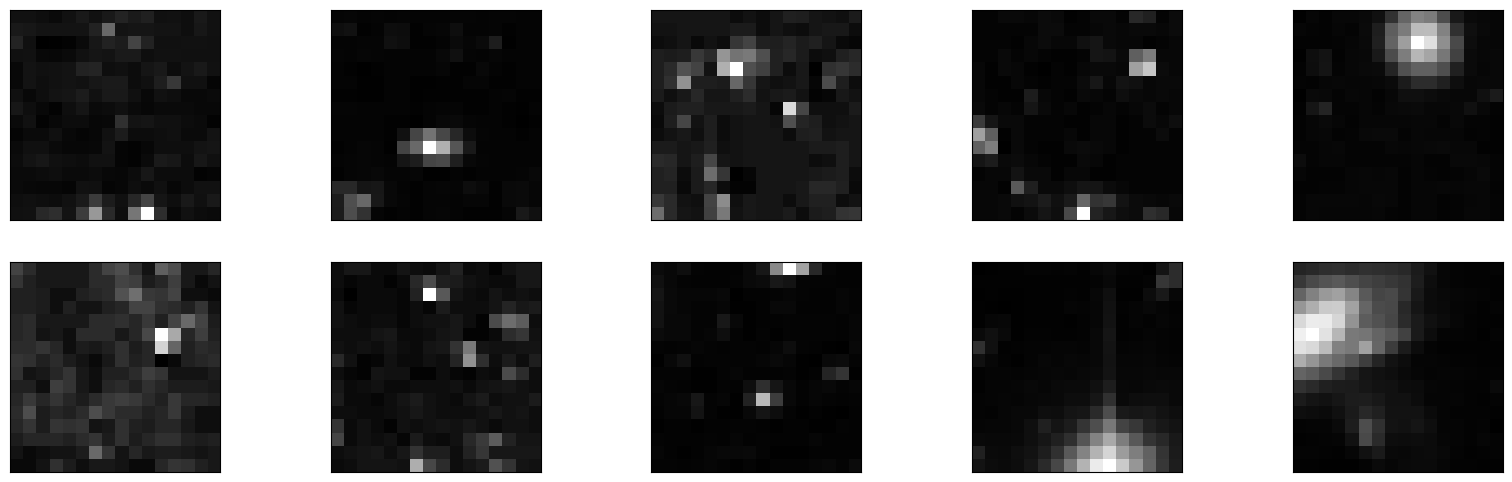

In [5]:
n_samples_show = 5
fig, axes = plt.subplots(nrows=2, ncols=n_samples_show, figsize=(20, 6))

for i in range(n_samples_show):

    axes[0,i].imshow(dataInput[i], cmap='gray')
    axes[0,i].set_xticks([])
    axes[0,i].set_yticks([])
    axes[1,i].imshow(dataInput[i+5], cmap='gray')
    axes[1,i].set_xticks([])
    axes[1,i].set_yticks([])    


In [6]:
import sys

!{sys.executable} -m pip install --upgrade --force-reinstall scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp312-cp312-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl (5.5 MB)
Using cached scipy-1.18.1-cp312-cp312-macosx_14_0_arm64.whl (20.5 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
  Attempting uninstall: threadpoolctl
    Found existing 

In [7]:
import numpy as np
from qiskit.circuit import Parameter
from qiskit import QuantumCircuit
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes

from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.connectors import TorchConnector
from torch.nn import Linear, CrossEntropyLoss, MSELoss
from torch.optim import LBFGS, SGD, Adam
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier, VQC

# Define the parity function
def parity(x):
    return f"{bin(x)}".count("1") % 2

# Model for LBFGS
np.random.seed(3)

nqubits = 6
num_inputs = 256
qc = QuantumCircuit(nqubits)

# Encoding
param_x = []
for i in range(num_inputs):
    param_x.append(Parameter('x' + str(i)))
for i in range(8):
    param_x.append(np.pi / 2)

# Assuming you have a function `encoding` defined elsewhere
feature_map = encoding(qc, param_x, 22)

# Optimizing circuit PQC
param_y = []
for i in range(nqubits * 2):
    param_y.append(Parameter('θ' + str(i)))

# Assuming you have a function `circuit15` defined elsewhere
ansatz = circuit15(qc, param_y)

# Compose the feature map and ansatz into the quantum circuit
qc.append(feature_map, range(nqubits))
qc.append(ansatz, range(nqubits))

# Use SamplerQNN instead of CircuitQNN
qnn2 = SamplerQNN(
    circuit=qc,
    input_params=feature_map.parameters,
    weight_params=ansatz.parameters,
    interpret=parity,
    output_shape=2
)

# Initialize weights for the QNN
initial_weights = 0.1 * (2 * np.random.rand(qnn2.num_weights) - 1)


# Learning Rate 0.05

In [9]:
# Define optimizer and loss function

model2 = TorchConnector(qnn2, initial_weights)

optimizer = LBFGS(model2.parameters(), lr=0.05)
f_loss = CrossEntropyLoss()

X = [normalizeData(dataInput[i].flatten()) for i in range(50)]
y01 = [data_target_o[i] for i in range(50)]

In [10]:
import numpy as np
import qiskit
import qiskit_machine_learning
import torch

print("NumPy:", np.__version__)
print("Qiskit:", qiskit.__version__)
print("Qiskit ML:", qiskit_machine_learning.__version__)
print("PyTorch:", torch.__version__)

NumPy: 2.5.4
Qiskit: 2.6.1
Qiskit ML: 0.9.1
PyTorch: 2.10.0


In [11]:
%pip install --upgrade "numpy>=2.0,<3"


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
import sys

!{sys.executable} -m pip install --upgrade --force-reinstall "numpy>=2.0,<3"

  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl (5.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langflow 1.7.2 requires certifi<2025.0.0,>=2023.11.17, but you have certifi 2026.1.4 which is incompatible.
langflow 1.7.2 requires scipy<1.16.2,>=1.14.1, but you have scipy 1.18.1 which is incompatible.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.5.4 which is incompatible.
tensorflow 2.17.0 requires numpy<2.0.0,>=1.26.0; python_version >= "3.12", but you have numpy 2.5.4 which is incompatible.
pymilvus 2.6.7 requires protobuf>=5.27.2, but you have protobuf 4.25.9 which is incompatible.
streamlit 1.32.0 r

In [13]:
import numpy as np
import qiskit

print("NumPy:", np.__version__)
print("Qiskit:", qiskit.__version__)
print("NumPy location:", np.__file__)
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

qc_test = QuantumCircuit(2)
qc_test.h(0)
qc_test.cx(0, 1)

sv = Statevector.from_instruction(qc_test)
print(sv)

NumPy: 2.5.4
Qiskit: 2.6.1
NumPy location: /opt/anaconda3/lib/python3.12/site-packages/numpy/__init__.py
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


In [14]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

qc_test = QuantumCircuit(2)
qc_test.h(0)
qc_test.cx(0, 1)

sv = Statevector.from_instruction(qc_test)

print(sv)

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


In [15]:
from qiskit_machine_learning.connectors import TorchConnector
from torch.optim import LBFGS
from torch.nn import CrossEntropyLoss

model2 = TorchConnector(qnn2, initial_weights)

optimizer = LBFGS(model2.parameters(), lr=0.05)

f_loss = CrossEntropyLoss()

In [16]:
from torch import Tensor

model2.train()

def closure():
    optimizer.zero_grad()
    loss = 0.0

    for x, y_target in zip(X, y01):
        output = model2(Tensor(x)).reshape(1, 2)
        loss += f_loss(output, Tensor([y_target]).long())

    loss.backward()
    print(loss.item())

    return loss

optimizer.step(closure)

35.64811325073242
35.54372024536133
34.583099365234375
33.46548080444336
34.92763137817383
33.943382263183594
33.3530387878418
33.160621643066406
32.918704986572266
32.557430267333984
32.2894172668457
32.128395080566406
32.01044845581055
31.910511016845703
31.814376831054688
31.707338333129883
31.57135009765625
31.401521682739258
31.247360229492188
31.13759994506836


tensor(35.6481, grad_fn=<AddBackward0>)

In [17]:
# define optimizer and loss function

model2 = TorchConnector(qnn2, initial_weights)

optimizer = LBFGS(model2.parameters(),lr=0.05)
f_loss = CrossEntropyLoss()

X= [normlaizeData(dataInput[i].flatten()) for i in range(50)]
y01= [data_target_o[i] for i in range(50)]

NameError: name 'normlaizeData' is not defined

In [ ]:
from torch import Tensor
# start training

model2.train()    # set model to training mode

# define objective function
def closure():
    optimizer.zero_grad()                                  # initialize gradient
    loss = 0.0                                             # initialize loss    
    for x, y_target in zip(X, y01):                        # evaluate batch loss
        output = model2(Tensor(x)).reshape(1, 2)           # forward pass
        loss += f_loss(output, Tensor([y_target]).long())
    loss.backward()                                        # backward pass
    print(loss.item())                                     # print loss
    return loss

# run optimizer
optimizer.step(closure)
optimizer.step(closure)

In [ ]:
# traning model accuracy
y_predict = []
for x in X:
    output = model2(Tensor(x))
    y_predict += [np.argmax(output.detach().numpy())]

print('Accuracy:', sum(y_predict == np.array(y01))/len(np.array(y01)))

# Learning rate 0.06

In [ ]:
# define optimizer and loss function
from torch import Tensor
model2 = TorchConnector(qnn2, initial_weights)

optimizer = LBFGS(model2.parameters(),lr=0.0006)
f_loss = CrossEntropyLoss()

X= [normlaizeData(dataInput[i].flatten()) for i in range(50)]
y01= [data_target_o[i] for i in range(50)]

y_predict = []
for x in X:
    output = model2(Tensor(x))
    y_predict += [np.argmax(output.detach().numpy())]

print('Accuracy:', sum(y_predict == np.array(y01))/len(np.array(y01)))

In [ ]:
from torch import Tensor
# start training

model2.train()    # set model to training mode

# define objective function
def closure():
    optimizer.zero_grad()                                  # initialize gradient
    loss = 0.0                                             # initialize loss    
    for x, y_target in zip(X, y01):                        # evaluate batch loss
        output = model2(Tensor(x)).reshape(1, 2)           # forward pass
        loss += f_loss(output, Tensor([y_target]).long())
    loss.backward()                                        # backward pass
    print(loss.item())                                     # print loss
    return loss

# run optimizer
optimizer.step(closure)
optimizer.step(closure)

In [ ]:
# traning model accuracy
y_predict = []
for x in X:
    output = model2(Tensor(x))
    y_predict += [np.argmax(output.detach().numpy())]

print('Accuracy:', sum(y_predict == np.array(y01))/len(np.array(y01)))

# Learning Rate 0.07

In [ ]:
# define optimizer and loss function
from torch import Tensor
model2 = TorchConnector(qnn2, initial_weights)

optimizer = LBFGS(model2.parameters(),lr=0.07)
f_loss = CrossEntropyLoss()

X= [normlaizeData(dataInput[i].flatten()) for i in range(50)]
y01= [data_target_o[i] for i in range(50)]

y_predict = []
for x in X:
    output = model2(Tensor(x))
    y_predict += [np.argmax(output.detach().numpy())]

print('Accuracy:', sum(y_predict == np.array(y01))/len(np.array(y01)))

In [ ]:
from torch import Tensor
# start training

model2.train()    # set model to training mode

# define objective function
def closure():
    optimizer.zero_grad()                                  # initialize gradient
    loss = 0.0                                             # initialize loss    
    for x, y_target in zip(X, y01):                        # evaluate batch loss
        output = model2(Tensor(x)).reshape(1, 2)           # forward pass
        loss += f_loss(output, Tensor([y_target]).long())
    loss.backward()                                        # backward pass
    print(loss.item())                                     # print loss
    return loss

# run optimizer
optimizer.step(closure)
optimizer.step(closure)

In [ ]:
# traning model accuracy
y_predict = []
for x in X:
    output = model2(Tensor(x))
    y_predict += [np.argmax(output.detach().numpy())]

print('Accuracy:', sum(y_predict == np.array(y01))/len(np.array(y01)))

# TestModel2

In [ ]:
target_o = [1 for i in range(25)]+[0 for i in range(25)]

pathY=r'../dataset/Original/galaxy1/'
pathN=r'../dataset/Original/no-galaxy1/'
nameN=''
nameY=''
inputY=[imageResize(callImage(i+1,pathY,nameY),16) for i in range(25)]
inputN=[imageResize(callImage(i+1,pathN,nameN),16) for i in range(25)]
input_combine = inputY+inputN

np.random.seed(0)
idx=np.array([int(i) for i in range(50)]).flatten()

np.random.shuffle(idx)

dataInput = list(input_combine[i] for i in idx )
dataTarget = list( imageBinarize(input_combine[i]) for i in idx )

data_target_o=list( target_o[i] for i in idx )

Xtest= [normlaizeData(dataInput[i].flatten()) for i in range(25)]
y01test= [data_target_o[i] for i in range(25)]

Xtest1= [normlaizeData(dataInput[i].flatten()) for i in range(50)]
y01test1= [data_target_o[i] for i in range(50)]

y_predict = []
for x in Xtest:
    output = model2(Tensor(x))
    y_predict += [np.argmax(output.detach().numpy())]

print('Accuracy25data:', sum(y_predict == np.array(y01test))/len(np.array(y01test)))

y_predict1 = []
for x in Xtest1:
    output = model2(Tensor(x))
    y_predict1 += [np.argmax(output.detach().numpy())]

print('Accuracy50data:', sum(y_predict1 == np.array(y01test1))/len(np.array(y01test1)))